<a href="https://colab.research.google.com/github/Nouranwael/DecodeLabs-Internship/blob/main/notebooks/plant_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

%pip install -q -U datasets pyarrow

from datasets import load_dataset
from collections import Counter

# Load PlantVillage images and metadata
dataset = load_dataset(
    "geraldmc/plantvillage-full",
    revision="v0.1.0",
    split="train"
)

print("Total images:", len(dataset))
print("Number of classes:", len(set(dataset["class_label"])))
print("Number of crops:", len(set(dataset["host"])))

print("\nCrops:")
print(Counter(dataset["host"]))

print("\nAvailable columns:")
print(dataset.column_names)

print("\nDataset loaded successfully!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 16.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/549 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

Total images: 54304
Number of classes: 38
Number of crops: 14

Crops:
Counter({'Tomato': 18160, 'Orange': 5507, 'Soybean': 5090, 'Grape': 4062, 'Corn (maize)': 3852, 'Apple': 3171, 'Peach': 2657, 'Pepper, bell': 2474, 'Potato': 2152, 'Cherry (including sour)': 1906, 'Squash': 1835, 'Strawberry': 1565, 'Blueberry': 1502, 'Raspberry': 371})

Available columns:
['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped']

Dataset loaded successfully!


Total images: 54304
Total classes: 38

Images per crop and disease:


,crop,disease,image_count
3,Apple,healthy,1645
0,Apple,Apple scab,630
1,Apple,Black rot,621
2,Apple,Cedar apple rust,275
4,Blueberry,healthy,1502
5,Cherry (including sour),Powdery mildew,1052
6,Cherry (including sour),healthy,854
8,Corn (maize),Common rust,1192
10,Corn (maize),healthy,1162
9,Corn (maize),Northern Leaf Blight,985


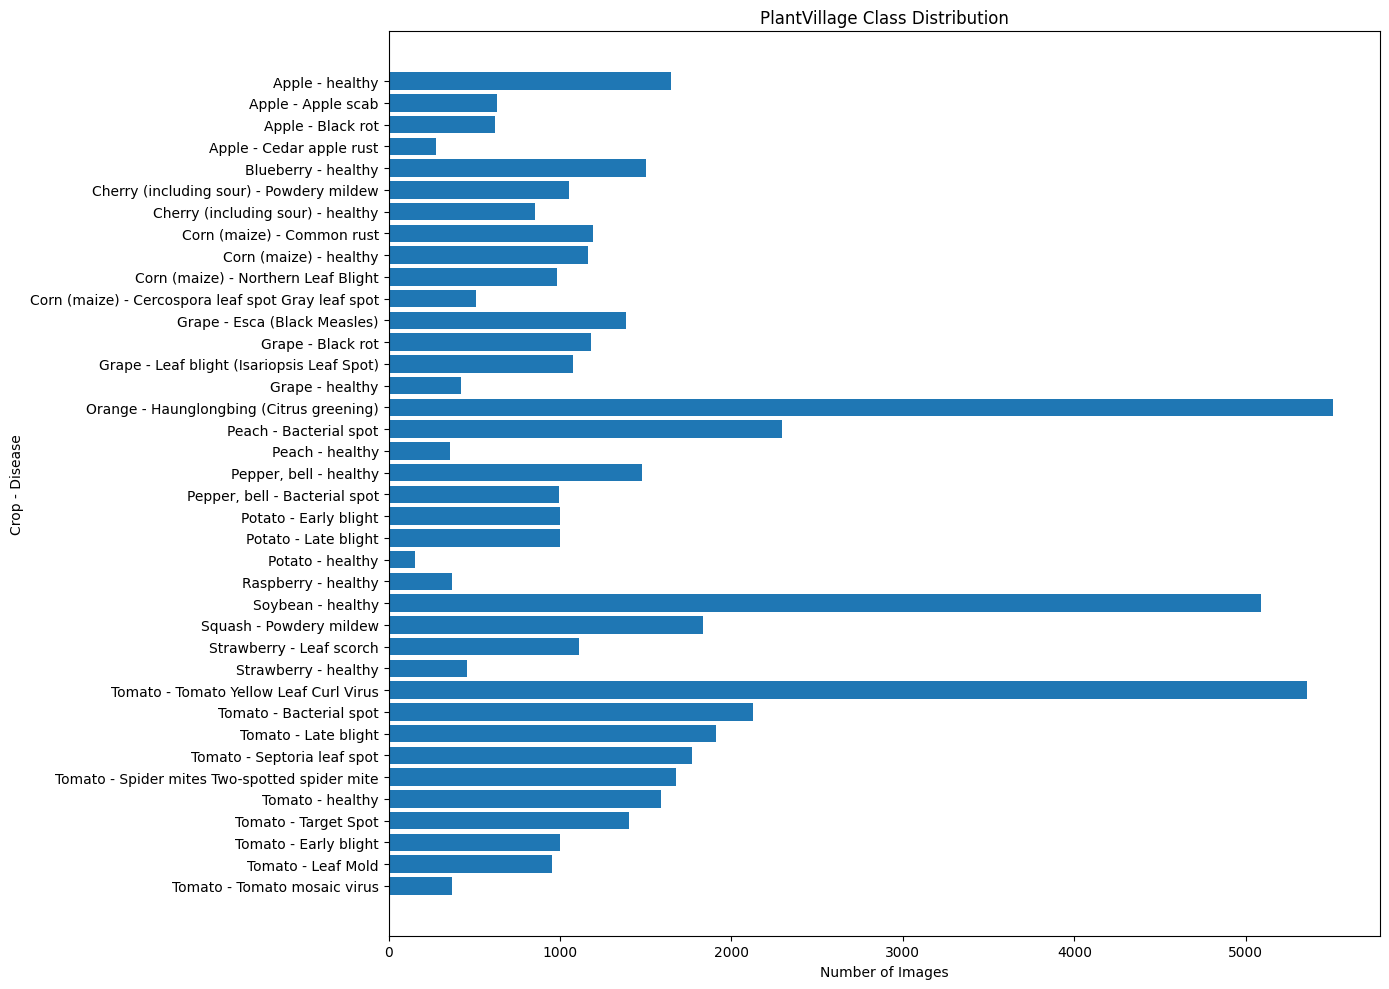


Existing split distribution:
split
train    43356
test     10948
Name: count, dtype: int64

Leaf grouping information:
0 missing leaf IDs


In [2]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract metadata only (without loading image pixels)
df = pd.DataFrame({
    "crop": dataset["host"],
    "disease": dataset["disease"],
    "class_label": dataset["class_label"],
    "split": dataset["split"],
    "leaf_id": dataset["leaf_id"]
})

# Count images per crop and disease
class_counts = (
    df.groupby(["crop", "disease"])
    .size()
    .reset_index(name="image_count")
    .sort_values(["crop", "image_count"], ascending=[True, False])
)

print("Total images:", len(df))
print("Total classes:", df["class_label"].nunique())
print("\nImages per crop and disease:")

display(class_counts)

# Class distribution chart
plt.figure(figsize=(14, 10))
plt.barh(
    class_counts["crop"] + " - " + class_counts["disease"],
    class_counts["image_count"]
)
plt.xlabel("Number of Images")
plt.ylabel("Crop - Disease")
plt.title("PlantVillage Class Distribution")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Check existing split values
print("\nExisting split distribution:")
print(df["split"].value_counts(dropna=False))

# Check leaf grouping metadata
print("\nLeaf grouping information:")
print(df["leaf_id"].isna().sum(), "missing leaf IDs")


In [3]:

import pandas as pd

# Verify leaf IDs do not overlap between train and test
train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

train_leaf_ids = set(train_df["leaf_id"])
test_leaf_ids = set(test_df["leaf_id"])

overlap = train_leaf_ids.intersection(test_leaf_ids)

print("Train images:", len(train_df))
print("Test images:", len(test_df))
print("Unique train leaf IDs:", len(train_leaf_ids))
print("Unique test leaf IDs:", len(test_leaf_ids))
print("Overlapping leaf IDs:", len(overlap))

if len(overlap) == 0:
    print("PASS: No leaf-ID overlap detected.")
else:
    print("WARNING: Leaf-ID overlap detected!")
    print("Examples:", list(overlap)[:10])

# Check uncommon leaf IDs
print("\nUnknown/fallback IDs:")
print(
    df["leaf_id"].astype(str)
    .str.contains("unknown|fallback", case=False)
    .sum()
)

# Check class coverage
print("\nClass coverage across splits:")
print(
    pd.crosstab(df["class_label"], df["split"])
)


Train images: 43356
Test images: 10948
Unique train leaf IDs: 19508
Unique test leaf IDs: 4877
Overlapping leaf IDs: 0
PASS: No leaf-ID overlap detected.

Unknown/fallback IDs:
0

Class coverage across splits:
split                                               test  train
class_label                                                    
Apple___Apple_scab                                   123    507
Apple___Black_rot                                    124    497
Apple___Cedar_apple_rust                              55    220
Apple___healthy                                      324   1321
Blueberry___healthy                                  278   1224
Cherry_(including_sour)___Powdery_mildew             252    800
Cherry_(including_sour)___healthy                    179    675
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot   103    410
Corn_(maize)___Common_rust_                          238    954
Corn_(maize)___Northern_Leaf_Blight                  197    788
Corn_(maize)___healthy

In [4]:

# Select our 5 target crops
selected_crops = [
    "Tomato",
    "Corn (maize)",
    "Grape",
    "Apple",
    "Pepper, bell"
]

# Filter metadata
selected_df = df[
    df["crop"].isin(selected_crops)
].copy()

# Select matching images
selected_dataset = dataset.select(
    selected_df.index.tolist()
)

print("Selected crops:", selected_df["crop"].nunique())
print("Selected classes:", selected_df["class_label"].nunique())
print("Total images:", len(selected_dataset))

print("\nImages per crop:")
print(selected_df["crop"].value_counts())

print("\nOriginal split distribution:")
print(selected_df["split"].value_counts())

print("\nClasses per crop:")
print(
    selected_df.groupby("crop")["class_label"].nunique()
)


Selected crops: 5
Selected classes: 24
Total images: 31719

Images per crop:
crop
Tomato          18160
Grape            4062
Corn (maize)     3852
Apple            3171
Pepper, bell     2474
Name: count, dtype: int64

Original split distribution:
split
train    25373
test      6346
Name: count, dtype: int64

Classes per crop:
crop
Apple            4
Corn (maize)     4
Grape            4
Pepper, bell     2
Tomato          10
Name: class_label, dtype: int64


In [5]:

import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

# Keep the selected five crops only
train_metadata = selected_df[
    selected_df["split"] == "train"
].copy().reset_index()

test_metadata = selected_df[
    selected_df["split"] == "test"
].copy()

# Create leaf-group-aware validation split
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_pos, val_pos = next(
    splitter.split(
        X=train_metadata,
        y=train_metadata["class_label"],
        groups=train_metadata["leaf_id"]
    )
)

# Original dataset indices
train_indices = train_metadata.iloc[train_pos]["index"].tolist()
val_indices = train_metadata.iloc[val_pos]["index"].tolist()
test_indices = test_metadata.index.tolist()

# Create datasets
train_ds = dataset.select(train_indices)
val_ds = dataset.select(val_indices)
test_ds = dataset.select(test_indices)

# Verify no shared leaf IDs
train_ids = set(train_ds["leaf_id"])
val_ids = set(val_ds["leaf_id"])
test_ids = set(test_ds["leaf_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# Verify all 24 classes are present
expected_classes = set(selected_df["class_label"])

for name, ds in [
    ("Training", train_ds),
    ("Validation", val_ds),
    ("Testing", test_ds)
]:
    actual_classes = set(ds["class_label"])
    print(f"{name}: {len(ds):,} images")
    print(f"Classes: {len(actual_classes)}/24")
    assert actual_classes == expected_classes

print("\nSUCCESS: Dataset splitting completed!")
print("No leaf-ID overlap detected.")


Training: 20,295 images
Classes: 24/24
Validation: 5,078 images
Classes: 24/24
Testing: 6,346 images
Classes: 24/24

SUCCESS: Dataset splitting completed!
No leaf-ID overlap detected.


In [6]:
import torch

print("GPU Available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

GPU Available: True
Device: Tesla T4


In [7]:
print("Training:", len(train_ds))
print("Validation:", len(val_ds))
print("Testing:", len(test_ds))

Training: 20295
Validation: 5078
Testing: 6346


In [8]:

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Label mapping for the selected 24 classes
class_names = sorted(set(selected_df["class_label"]))
class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class PlantDiseaseDataset(Dataset):
    def __init__(self, data, transform):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        item = self.data[index]

        image = item["image"].convert("RGB")
        label = class_to_idx[item["class_label"]]

        return (
            self.transform(image),
            torch.tensor(label, dtype=torch.long)
        )

# PyTorch datasets
train_data = PlantDiseaseDataset(train_ds, train_transform)
val_data = PlantDiseaseDataset(val_ds, eval_transform)
test_data = PlantDiseaseDataset(test_ds, eval_transform)

# DataLoaders
train_loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Classes:", len(class_names))
print("DataLoaders ready!")


Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Classes: 24
DataLoaders ready!


In [9]:

from google.colab import drive

drive.mount(
    "/content/drive",
    force_remount=True,
    timeout_ms=120000
)


Mounted at /content/drive


In [ ]:

import os

SAVE_DIR = "/content/drive/MyDrive/SmartFarm_AI/Vision_Model"

os.makedirs(SAVE_DIR, exist_ok=True)

print("Save directory ready:", SAVE_DIR)


Save directory ready: /content/drive/MyDrive/SmartFarm_AI/Vision_Model


In [ ]:

import torch
import torch.nn as nn
import numpy as np

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)
from collections import Counter

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.manual_seed(42)
np.random.seed(42)

# Load pretrained model
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Replace final layer for 24 classes
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(
    num_features,
    len(class_names)
)

model = model.to(device)

# Class weights based on training split only
class_counts = Counter(train_ds["class_label"])

counts = np.array(
    [class_counts[name] for name in class_names],
    dtype=np.float32
)

class_weights = counts.sum() / (len(counts) * counts)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=1
)

print("Device:", device)
print("Model: EfficientNet-B0")
print("Classes:", len(class_names))
print("Trainable Parameters:", sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
))
print("Model initialized successfully!")


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 47.9MB/s]


Device: cuda
Model: EfficientNet-B0
Classes: 24
Trainable Parameters: 4038292
Model initialized successfully!


In [ ]:

import os
import json
import torch
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

EPOCHS = 10
PATIENCE = 3

best_f1 = -1.0
patience_counter = 0
history = []

checkpoint_path = os.path.join(
    SAVE_DIR, "best_efficientnet_b0.pth"
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

for epoch in range(EPOCHS):

    # TRAINING
    model.train()
    train_loss = 0.0
    train_preds = []
    train_targets = []

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} - Training"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_preds.extend(predictions.detach().cpu().tolist())
        train_targets.extend(labels.cpu().tolist())

    train_loss /= len(train_data)

    train_acc = accuracy_score(train_targets, train_preds)
    train_f1 = f1_score(
        train_targets, train_preds,
        average="macro",
        zero_division=0
    )

    # VALIDATION
    model.eval()
    val_loss = 0.0
    val_preds = []
    val_targets = []

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader,
            desc="Validation"
        ):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_preds.extend(predictions.cpu().tolist())
            val_targets.extend(labels.cpu().tolist())

    val_loss /= len(val_data)

    val_acc = accuracy_score(val_targets, val_preds)
    val_f1 = f1_score(
        val_targets, val_preds,
        average="macro",
        zero_division=0
    )

    scheduler.step(val_f1)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Train Macro F1: {train_f1:.4f}")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Accuracy: {val_acc:.4f}")
    print(f"Val Macro F1: {val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        patience_counter = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "architecture": "efficientnet_b0",
            "epoch": epoch + 1,
            "val_macro_f1": val_f1
        }, checkpoint_path)

        print("Best model saved!")

    else:
        patience_counter += 1
        print(
            f"Early stopping: "
            f"{patience_counter}/{PATIENCE}"
        )

    with open(
        os.path.join(SAVE_DIR, "training_history.json"),
        "w"
    ) as f:
        json.dump(history, f, indent=2)

    if patience_counter >= PATIENCE:
        print("Early stopping triggered!")
        break

print("\nTraining completed!")
print("Best Validation Macro F1:", round(best_f1, 4))
print("Saved model:", checkpoint_path)


Epoch 1/10 - Training:   0%|          | 0/635 [00:00<?, ?it/s]

Validation:   0%|          | 0/159 [00:00<?, ?it/s]


Epoch 1/10
Train Loss: 0.6203
Train Accuracy: 0.8643
Train Macro F1: 0.8459
Val Loss: 0.0734
Val Accuracy: 0.9807
Val Macro F1: 0.9771
Best model saved!


Epoch 2/10 - Training:   0%|          | 0/635 [00:00<?, ?it/s]

Validation:   0%|          | 0/159 [00:00<?, ?it/s]

...

Epoch 7/10 - Training:   0%|          | 0/635 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e87084d5f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: Exception ignored in: can only test a child process<function _MultiProcessingDataLoaderIter.__del__ at 0x7e87084d5f80>

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7e87084d5f80>self._shutdown_workers()

Traceback (most recent call last):
  File "/usr/local/lib/pyt

Validation:   0%|          | 0/159 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e87084d5f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionErrorcan only test a child process: 
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e87084d5f80>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e87084d5f80>
Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/u


Epoch 7/10
Train Loss: 0.0134
Train Accuracy: 0.9960
Train Macro F1: 0.9951
Val Loss: 0.0276
Val Accuracy: 0.9927
Val Macro F1: 0.9898
Early stopping: 3/3
Early stopping triggered!

Training completed!
Best Validation Macro F1: 0.9899
Saved model: /content/drive/MyDrive/SmartFarm_AI/Vision_Model/best_efficientnet_b0.pth


In [ ]:

import os
import torch
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from torchvision.models import efficientnet_b0

# Load best checkpoint
checkpoint_path = os.path.join(
    SAVE_DIR, "best_efficientnet_b0.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Rebuild model with saved class count
model = efficientnet_b0(weights=None)
num_features = model.classifier[1].in_features

model.classifier[1] = torch.nn.Linear(
    num_features,
    len(checkpoint["class_names"])
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

saved_classes = checkpoint["class_names"]

# Ensure label order matches training
assert saved_classes == class_names

all_predictions = []
all_targets = []

with torch.inference_mode():
    for images, labels in tqdm(
        test_loader,
        desc="Internal Testing"
    ):
        images = images.to(device)

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().tolist()
        )
        all_targets.extend(
            labels.tolist()
        )

# Overall metrics
accuracy = accuracy_score(
    all_targets, all_predictions
)

precision = precision_score(
    all_targets, all_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_targets, all_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_targets, all_predictions,
    average="macro",
    zero_division=0
)

print("\nINTERNAL TEST RESULTS")
print("----------------------")
print(f"Accuracy:  {accuracy:.4%}")
print(f"Precision: {precision:.4%}")
print(f"Recall:    {recall:.4%}")
print(f"Macro F1:  {f1:.4%}")

# Class-level report
print("\nCLASSIFICATION REPORT\n")

print(
    classification_report(
        all_targets,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

# Save results
results_df = pd.DataFrame({
    "true_label": [
        class_names[i] for i in all_targets
    ],
    "predicted_label": [
        class_names[i] for i in all_predictions
    ]
})

results_path = os.path.join(
    SAVE_DIR, "internal_test_predictions.csv"
)

results_df.to_csv(results_path, index=False)

print("\nResults saved to:", results_path)


Internal Testing:   0%|          | 0/199 [00:00<?, ?it/s]


INTERNAL TEST RESULTS
----------------------
Accuracy:  99.4485%
Precision: 99.3032%
Recall:    99.2728%
Macro F1:  99.2861%

CLASSIFICATION REPORT

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.98      0.99      0.99       123
                                 Apple___Black_rot       1.00      1.00      1.00       124
                          Apple___Cedar_apple_rust       1.00      1.00      1.00        55
                                   Apple___healthy       0.99      1.00      1.00       324
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.95      0.94      0.95       103
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       238
               Corn_(maize)___Northern_Leaf_Blight       0.97      0.97      0.97       197
                            Corn_(maize)___healthy       1.00      1.00      1.00       232
                     